<a href="https://colab.research.google.com/github/wildemar66/Project_Analisis_churn/blob/main/notebooks/Data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
# menghubungkun google colab dan google drive
from google.colab import drive
drive.mount('/content/drive')

# jalur folder
BASE_PATH = '/content/drive/MyDrive/Project_Analisis_churn'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Load Data

In [36]:
# load data
df = pd.read_csv(f'{BASE_PATH}/Data/Raw/Telco_customer_churn.csv')

In [37]:
df.sample(5)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
4080,3308-MHOOC,1,United States,California,Scotia,95565,"40.440636, -124.098739",40.440636,-124.098739,Male,No,No,Yes,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.20,19.2,No,0,76,3383,NaN
3996,0428-IKYCP,1,United States,California,Sonora,95370,"37.982716, -120.343732",37.982716,-120.343732,Male,No,Yes,No,22,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),87.00,1850.65,No,0,49,5233,NaN
4153,3911-RSNHI,1,United States,California,Rocklin,95765,"38.823278, -121.281856",38.823278,-121.281856,Female,No,Yes,No,71,No,No phone service,DSL,No,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),61.40,4310.35,No,0,37,5119,NaN
1124,6425-YQLLO,1,United States,California,Pinole,94564,"37.996462, -122.293716",37.996462,-122.293716,Female,Yes,Yes,No,66,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,One year,Yes,Credit card (automatic),105.95,6975.25,Yes,1,86,6117,Don't know
2303,8270-RKSAP,1,United States,California,Anaheim,92801,"33.844983, -117.952151",33.844983,-117.952151,Male,No,No,No,9,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.50,597.9,No,0,37,3198,NaN


# Explorasi awal

In [38]:
# info data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

* Kesalahan type data dikolom "Total Charges" (object --> float). akan diganti dengan type data float.
* Missing value dikolom "Churn Reason". kolom churn reason memaang hanya diisi apa bila customer churn.

In [39]:
# ganti type data dikolom "Total Charges"
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df.info()
print('Type data dikolom sudah diganti menjadi numerik')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [40]:
# cek value dalam kolom
kolom_kategori = df[['Country','State','City','Gender','Senior Citizen',
                     'Partner','Dependents','Phone Service','Multiple Lines',
                     'Internet Service','Online Security','Online Backup','Device Protection',
                     'Tech Support','Streaming TV','Streaming Movies','Contract','Paperless Billing',
                     'Payment Method','Churn Label']]

for kolom in kolom_kategori.columns:
  print('============================')
  print(f'Value counts untuk kolom: {kolom}')
  print(kolom_kategori[kolom].value_counts())

Value counts untuk kolom: Country
Country
United States    7043
Name: count, dtype: int64
Value counts untuk kolom: State
State
California    7043
Name: count, dtype: int64
Value counts untuk kolom: City
City
Los Angeles               305
San Diego                 150
San Jose                  112
Sacramento                108
San Francisco             104
Fresno                     64
Long Beach                 60
Oakland                    52
Stockton                   44
Bakersfield                40
Glendale                   40
Berkeley                   32
Riverside                  32
Pasadena                   30
Whittier                   30
Irvine                     28
San Bernardino             28
Santa Barbara              28
Anaheim                    28
Modesto                    28
Inglewood                  25
Torrance                   25
Santa Monica               25
Burbank                    25
Chula Vista                25
Santa Rosa                 24
Santa Ana  

* Dikolom "online security,online backup,device protection,tech support,streaming tv,dan streaming movie" memiliki value "No internet service" yang sebenarnya sama dengan "No". untuk itu kita akan melakukan standarisasi nilai menjadi "No".
* Dikolom "multiple lines" juga terdapat value "No phone service" yang sama dengan "No". kita akan melakukan standarisasi nilia menjadi "No".

In [41]:
# Standarisasi Nila pada kolom kategori
df = df.replace(['No internet service','No phone service'],'No')

In [42]:
df.sample(5)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
5462,3688-FTHLT,1,United States,California,Flournoy,96029,"39.84784, -122.544556",39.847840,-122.544556,Female,No,No,No,16,Yes,Yes,DSL,No,No,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),63.05,1067.05,No,0,73,3214,NaN
6279,5656-JAMLX,1,United States,California,Greenbrae,94904,"37.946617, -122.563571",37.946617,-122.563571,Male,No,No,No,62,Yes,No,No,No,No,No,No,No,No,Two year,No,Bank transfer (automatic),19.85,1253.65,No,0,45,4278,NaN
1858,0093-XWZFY,1,United States,California,Desert Hot Springs,92241,"33.832799, -116.250973",33.832799,-116.250973,Male,No,No,No,40,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),104.50,4036.85,Yes,1,93,2832,Competitor had better devices
2408,9944-AEXBM,1,United States,California,Casmalia,93429,"34.866032, -120.536546",34.866032,-120.536546,Male,No,No,No,32,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),85.65,2664.30,No,0,26,2383,NaN
5749,8486-AYEQH,1,United States,California,Guatay,91931,"32.857946, -116.561917",32.857946,-116.561917,Female,No,No,No,31,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,76.05,2227.80,No,0,63,2421,NaN


In [43]:
# cek value dalam kolom
kolom_kategori = df[['Country','State','City','Gender','Senior Citizen',
                     'Partner','Dependents','Phone Service','Multiple Lines',
                     'Internet Service','Online Security','Online Backup','Device Protection',
                     'Tech Support','Streaming TV','Streaming Movies','Contract','Paperless Billing',
                     'Payment Method','Churn Label']]

for kolom in kolom_kategori.columns:
  print('============================')
  print(f'Value counts untuk kolom: {kolom}')
  print(kolom_kategori[kolom].value_counts())

Value counts untuk kolom: Country
Country
United States    7043
Name: count, dtype: int64
Value counts untuk kolom: State
State
California    7043
Name: count, dtype: int64
Value counts untuk kolom: City
City
Los Angeles               305
San Diego                 150
San Jose                  112
Sacramento                108
San Francisco             104
Fresno                     64
Long Beach                 60
Oakland                    52
Stockton                   44
Bakersfield                40
Glendale                   40
Berkeley                   32
Riverside                  32
Pasadena                   30
Whittier                   30
Irvine                     28
San Bernardino             28
Santa Barbara              28
Anaheim                    28
Modesto                    28
Inglewood                  25
Torrance                   25
Santa Monica               25
Burbank                    25
Chula Vista                25
Santa Rosa                 24
Santa Ana  

# Missing Value

In [44]:
# cek missing value
df.isna().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


* Pada kolom Churn reason terdapat missing value sebesar 5174 baris. Kolom churn reason hanya diisi oleh customer yang curn, wajar terdapat nila NaN.
* kolom Total Charges tedapat missing value (11). nilai Nan tersebut dikarenakan dikolom "tenur month" masih 0 bulan (customer baru). nanti akan dicek kembali dan diisi dengan 0 jika kolom "tenure month" = 0

In [45]:
df.sample(5)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
3700,9135-MGVPY,1,United States,California,Sanger,93657,"36.819628, -119.440414",36.819628,-119.440414,Male,No,Yes,No,69,Yes,No,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Mailed check,84.70,5878.90,No,0,70,5345,NaN
2619,6614-YOLAC,1,United States,California,Oakland,94602,"37.803883, -122.208417",37.803883,-122.208417,Female,No,Yes,No,71,No,No,DSL,Yes,Yes,No,Yes,Yes,Yes,Two year,No,Mailed check,58.65,4145.25,No,0,48,4151,NaN
3280,5668-MEISB,1,United States,California,Hacienda Heights,91745,"33.998471, -117.973758",33.998471,-117.973758,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),106.10,7657.40,No,0,34,5146,NaN
5140,3486-HOOGQ,1,United States,California,San Jose,95128,"37.316146, -121.936285",37.316146,-121.936285,Female,No,Yes,Yes,70,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Bank transfer (automatic),79.70,5743.30,No,0,41,4848,NaN
2809,7182-OVLBJ,1,United States,California,Kenwood,95452,"38.419525, -122.521585",38.419525,-122.521585,Female,No,Yes,Yes,62,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),101.15,6638.35,No,0,36,5735,NaN


In [46]:
# cek nilai Nan dikolom "Total Charges"
nan_totalcharges = df[df['Total Charges'].isna()]
display(nan_totalcharges)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,No,Yes,No,0,No,No,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,No,No,No,0,Yes,No,No,No,No,No,No,No,No,Two year,No,Mailed check,20.25,NaN,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,No,Yes,No,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,No,Yes,Yes,0,Yes,Yes,No,No,No,No,No,No,No,Two year,No,Mailed check,25.75,NaN,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,No,Yes,No,0,No,No,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,No,Yes,Yes,0,Yes,No,No,No,No,No,No,No,No,Two year,No,Mailed check,19.85,NaN,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,No,Yes,Yes,0,Yes,Yes,No,No,No,No,No,No,No,Two year,No,Mailed check,25.35,NaN,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,No,Yes,Yes,0,Yes,No,No,No,No,No,No,No,No,Two year,No,Mailed check,20.00,NaN,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,No,Yes,Yes,0,Yes,No,No,No,No,No,No,No,No,One year,Yes,Mailed check,19.70,NaN,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,0,44,2342,NaN


Dari hasil pemeriksaan nilai Nan dikolom "Total charges" disebabkan karena customer yang baru berlangganan dengan Tenure month masih 0 bulan. kita akan mengganti nilai Nan menjadi 0.

In [47]:
# ganti nilai Nan menjadi 0 dikolom "Total charges"
df['Total Charges'] = df['Total Charges'].fillna(0)

In [48]:
df.isna().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


# Data duplikat

In [49]:
# cek data duplikat. jika hasilnya 1, maka tidak da duplikat.
len(df.duplicated())/len(df)

1.0

* Tidak ada data duplikat

# Outlier

In [50]:
# buat fungsi untuk cek outlier dikolom numerik
def cek_outlier(df,kolom):
  # tentukan ukuran
  plt.figure(figsize=(16,4))

  # Histogram
  plt.subplot(1,3,1)
  sns.histplot(df[kolom],bins=30)
  plt.title(f"Histogram {kolom}")

  # plot q-q
  plt.subplot(1,3,2)
  stats.probplot(df[kolom],dist="norm",plot=plt)
  plt.title(f"Q-Q Plot {kolom}")

  # boxplot
  plt.subplot(1,3,3)
  sns.boxplot(y=df[kolom])
  plt.title(f"Boxplot {kolom}")
  plt.tight_layout

  plt.show()

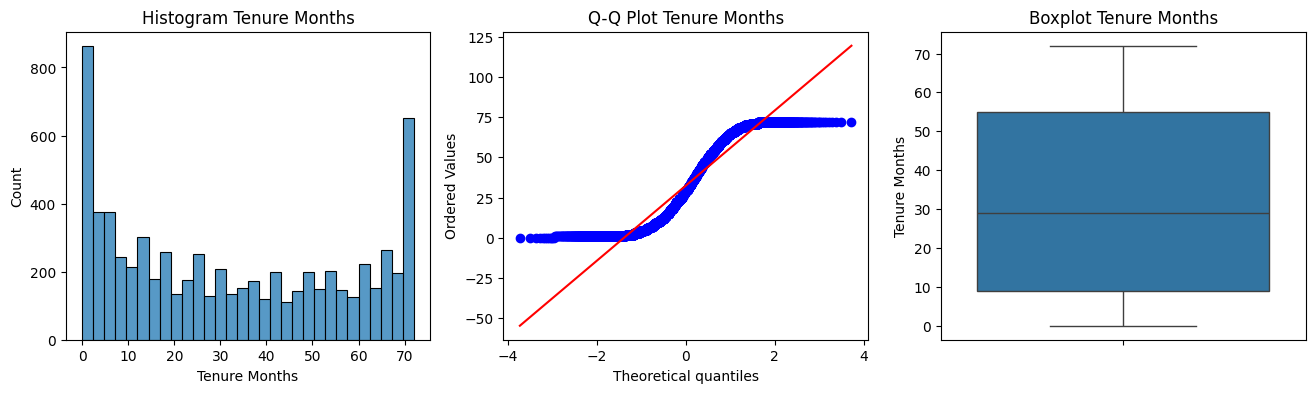

In [51]:
# cek outlier dikolom "Tenure months"
cek_outlier(df,'Tenure Months')

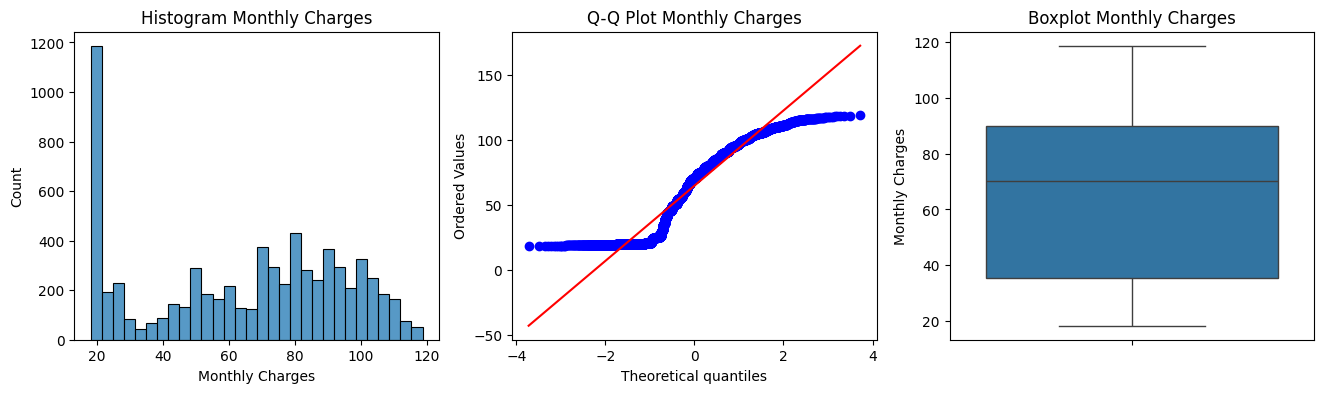

In [52]:
# cek outlier dikolom "Monthly charges"
cek_outlier(df,'Monthly Charges')

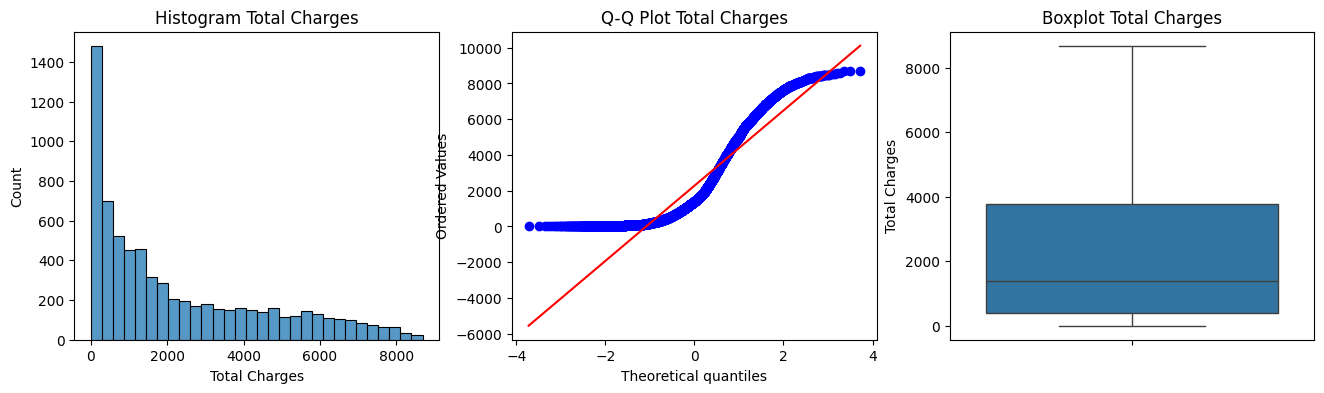

In [54]:
# cek outlier dikolom "Total charges"
cek_outlier(df,'Total Charges')

* Tidak ada outlier dikolom numerik
* Semua nilai dikolom numerik masuk akal secara bisnis.

In [55]:
# simpan data bersih
df.to_csv(f'{BASE_PATH}/Data/Processed/data_bersih.csv')